# Drzewa decyzyjne – case study: odejścia klientów (Churn)

**Plan notatnika:**
1. Dane i problem biznesowy
2. Przygotowanie danych
3. Podział i baseline
4. Drzewo decyzyjne
5. Dane niezbalansowane – `class_weight`
6. Dobór hiperparametrów (`GridSearchCV`)
7. Podsumowanie

**Churn** to odejście klienta (rezygnacja z usług). Zbiór `churn.csv` opisuje klientów firmy telekomunikacyjnej. Zadanie: przewidzieć, którzy klienci **odejdą** (`churn = True`), aby firma mogła zaproponować im ofertę zatrzymującą.

In [3]:
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 1. Dane i problem biznesowy

state	Stan USA, w którym mieszka klient (np. KS – Kansas, OH – Ohio).
account length	Długość posiadania konta u operatora, wyrażona w dniach.
area code	Telefoniczny numer kierunkowy obszaru, np. 415, 408.
phone number	Numer telefonu klienta, pełniący funkcję identyfikatora.
international plan	Czy klient ma aktywny plan rozmów międzynarodowych (yes/no).
voice mail plan	Czy klient korzysta z usługi poczty głosowej (yes/no).
number vmail messages	Liczba wiadomości poczty głosowej.
total day minutes	Łączna liczba minut rozmów w ciągu dnia.
total day calls	Łączna liczba połączeń wykonanych w ciągu dnia.
total day charge	Łączna opłata za rozmowy dzienne (USD).
total eve minutes	Łączna liczba minut rozmów wieczornych.
total eve calls	Łączna liczba połączeń wieczornych.
total eve charge	Łączna opłata za rozmowy wieczorne (USD).
total night minutes	Łączna liczba minut rozmów nocnych.
total night calls	Łączna liczba połączeń nocnych.
total night charge	Łączna opłata za rozmowy nocne (USD).
total intl minutes	Łączna liczba minut rozmów międzynarodowych.
total intl calls	Łączna liczba połączeń międzynarodowych.
total intl charge	Łączna opłata za rozmowy międzynarodowe (USD).
customer service calls	Liczba połączeń klienta z działem obsługi klienta.
churn	Zmienna docelowa: True – klient odszedł, False – klient pozostał.

In [4]:
df = pd.read_csv('churn.csv')
print('Kształt:', df.shape)
print('Braki danych:', df.isna().sum().sum())
df.head()

Kształt: (3333, 21)
Braki danych: 0


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   str    
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   str    
 4   international plan      3333 non-null   str    
 5   voice mail plan         3333 non-null   str    
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   int64  
 15

In [6]:
df.describe().round(2)

,account length,area code,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls
count,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00
mean,101.06,437.18,8.10,179.78,100.44,30.56,200.98,100.11,17.08,200.87,100.11,9.04,10.24,4.48,2.76,1.56
std,39.82,42.37,13.69,54.47,20.07,9.26,50.71,19.92,4.31,50.57,19.57,2.28,2.79,2.46,0.75,1.32
min,1.00,408.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,23.20,33.00,1.04,0.00,0.00,0.00,0.00
25%,74.00,408.00,0.00,143.70,87.00,24.43,166.60,87.00,14.16,167.00,87.00,7.52,8.50,3.00,2.30,1.00
50%,101.00,415.00,0.00,179.40,101.00,30.50,201.40,100.00,17.12,201.20,100.00,9.05,10.30,4.00,2.78,1.00
75%,127.00,510.00,20.00,216.40,114.00,36.79,235.30,114.00,20.00,235.30,113.00,10.59,12.10,6.00,3.27,2.00
max,243.00,510.00,51.00,350.80,165.00,59.64,363.70,170.00,30.91,395.00,175.00,17.77,20.00,20.00,5.40,9.00


Zmienna celu `churn` ma wartości `True` (klient odszedł) i `False` (został). Sprawdźmy jej rozkład:

In [7]:
print(df['churn'].value_counts())
print()
print(df['churn'].value_counts(normalize=True).round(3))

churn
False    2850
True      483
Name: count, dtype: int64

churn
False    0.855
True     0.145
Name: proportion, dtype: float64


Klientów, którzy odeszli, jest tylko ok. 14,5%. To **dane niezbalansowane** – klasa, na której nam zależy, jest rzadka. Ma to duże znaczenie dla wyboru metryki (patrz niżej).

## 2. Przygotowanie danych

Z cech usuwamy kolumny, które nie pomagają w uogólnianiu:
- `phone number` – unikalny identyfikator klienta (nie niesie informacji o zachowaniu, a drzewo mogłoby się go „nauczyć” na pamięć),
- `state` – 51 wartości; po zakodowaniu dałoby 50 dodatkowych kolumn,
- `area code` – kod numeryczny, de facto kategoria powiązana ze stanem.

Kolumny `yes`/`no` (`international plan`, `voice mail plan`) kodujemy na 0/1 przez `get_dummies`. Skalowania nie potrzeba – drzewa są odporne na różne skale cech.

In [8]:
X = df.drop(columns=['state', 'area code', 'phone number', 'churn'])
X = pd.get_dummies(X, drop_first=True, dtype=int)      # drop_first: jedna kolumna 0/1 dla każdej cechy yes/no
y = df['churn'].astype(int)                              # True/False -> 1/0

X.head()

,account length,number vmail messages,total day minutes,total day calls,total day charge,total eve minutes,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,international plan_yes,voice mail plan_yes
0,128,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0,1
1,107,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0,1
2,137,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0,0
3,84,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,1,0
4,75,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,1,0


Uwaga: kolumny `total day minutes` i `total day charge` (oraz analogiczne dla wieczoru, nocy i połączeń zagranicznych) są niemal identyczne – opłata jest wprost proporcjonalna do liczby minut. Drzewu to nie szkodzi, ale ważność cechy rozdzieli się między obie kolumny.

## 3. Podział i baseline

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print('Zbiór treningowy:', X_train.shape, '  testowy:', X_test.shape)
print('Udział churn w zbiorze treningowym:', round(y_train.mean(), 3), ' w testowym:', round(y_test.mean(), 3))

Zbiór treningowy: (2499, 17)   testowy: (834, 17)
Udział churn w zbiorze treningowym: 0.145  w testowym: 0.145


In [12]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Accuracy baseline: {baseline.score(X_test, y_test):.3f}')
print(f'Recall baseline:   {recall_score(y_test, baseline.predict(X_test)):.3f}')

Accuracy baseline: 0.855
Recall baseline:   0.000


Baseline, który **nikogo nie oznacza jako odchodzącego**, ma ok. 85,5% trafności, ale wykrywa 0% odchodzących klientów (`recall = 0`). To pułapka: przy danych niezbalansowanych `accuracy` jest mylące. Będziemy patrzeć głównie na:
- **recall** (czułość) – jaki odsetek odchodzących klientów wykryliśmy,
- **precision** – jaki odsetek oznaczonych klientów faktycznie odszedłby,
- **F1** – kompromis między nimi.

## 4. Drzewo decyzyjne

In [45]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f'Accuracy trening: {model.score(X_train, y_train):.3f}')
print(f'Accuracy test:    {model.score(X_test, y_test):.3f}')
print()
print(classification_report(y_test, y_pred, target_names=['został', 'odszedł']))

Accuracy trening: 0.908
Accuracy test:    0.902

              precision    recall  f1-score   support

      został       0.90      0.99      0.95       713
     odszedł       0.88      0.37      0.52       121

    accuracy                           0.90       834
   macro avg       0.89      0.68      0.73       834
weighted avg       0.90      0.90      0.88       834



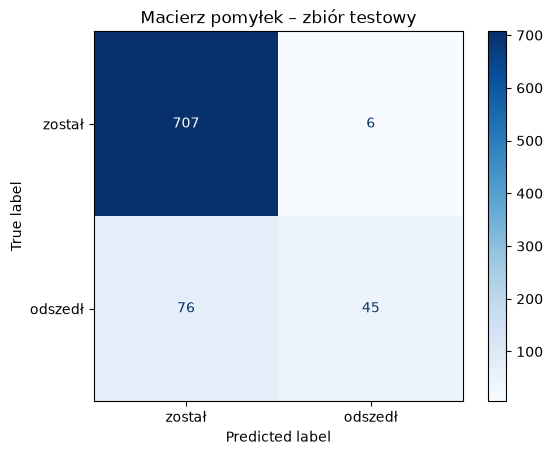

In [46]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['został', 'odszedł'], cmap='Blues')
plt.title('Macierz pomyłek – zbiór testowy')
plt.show()

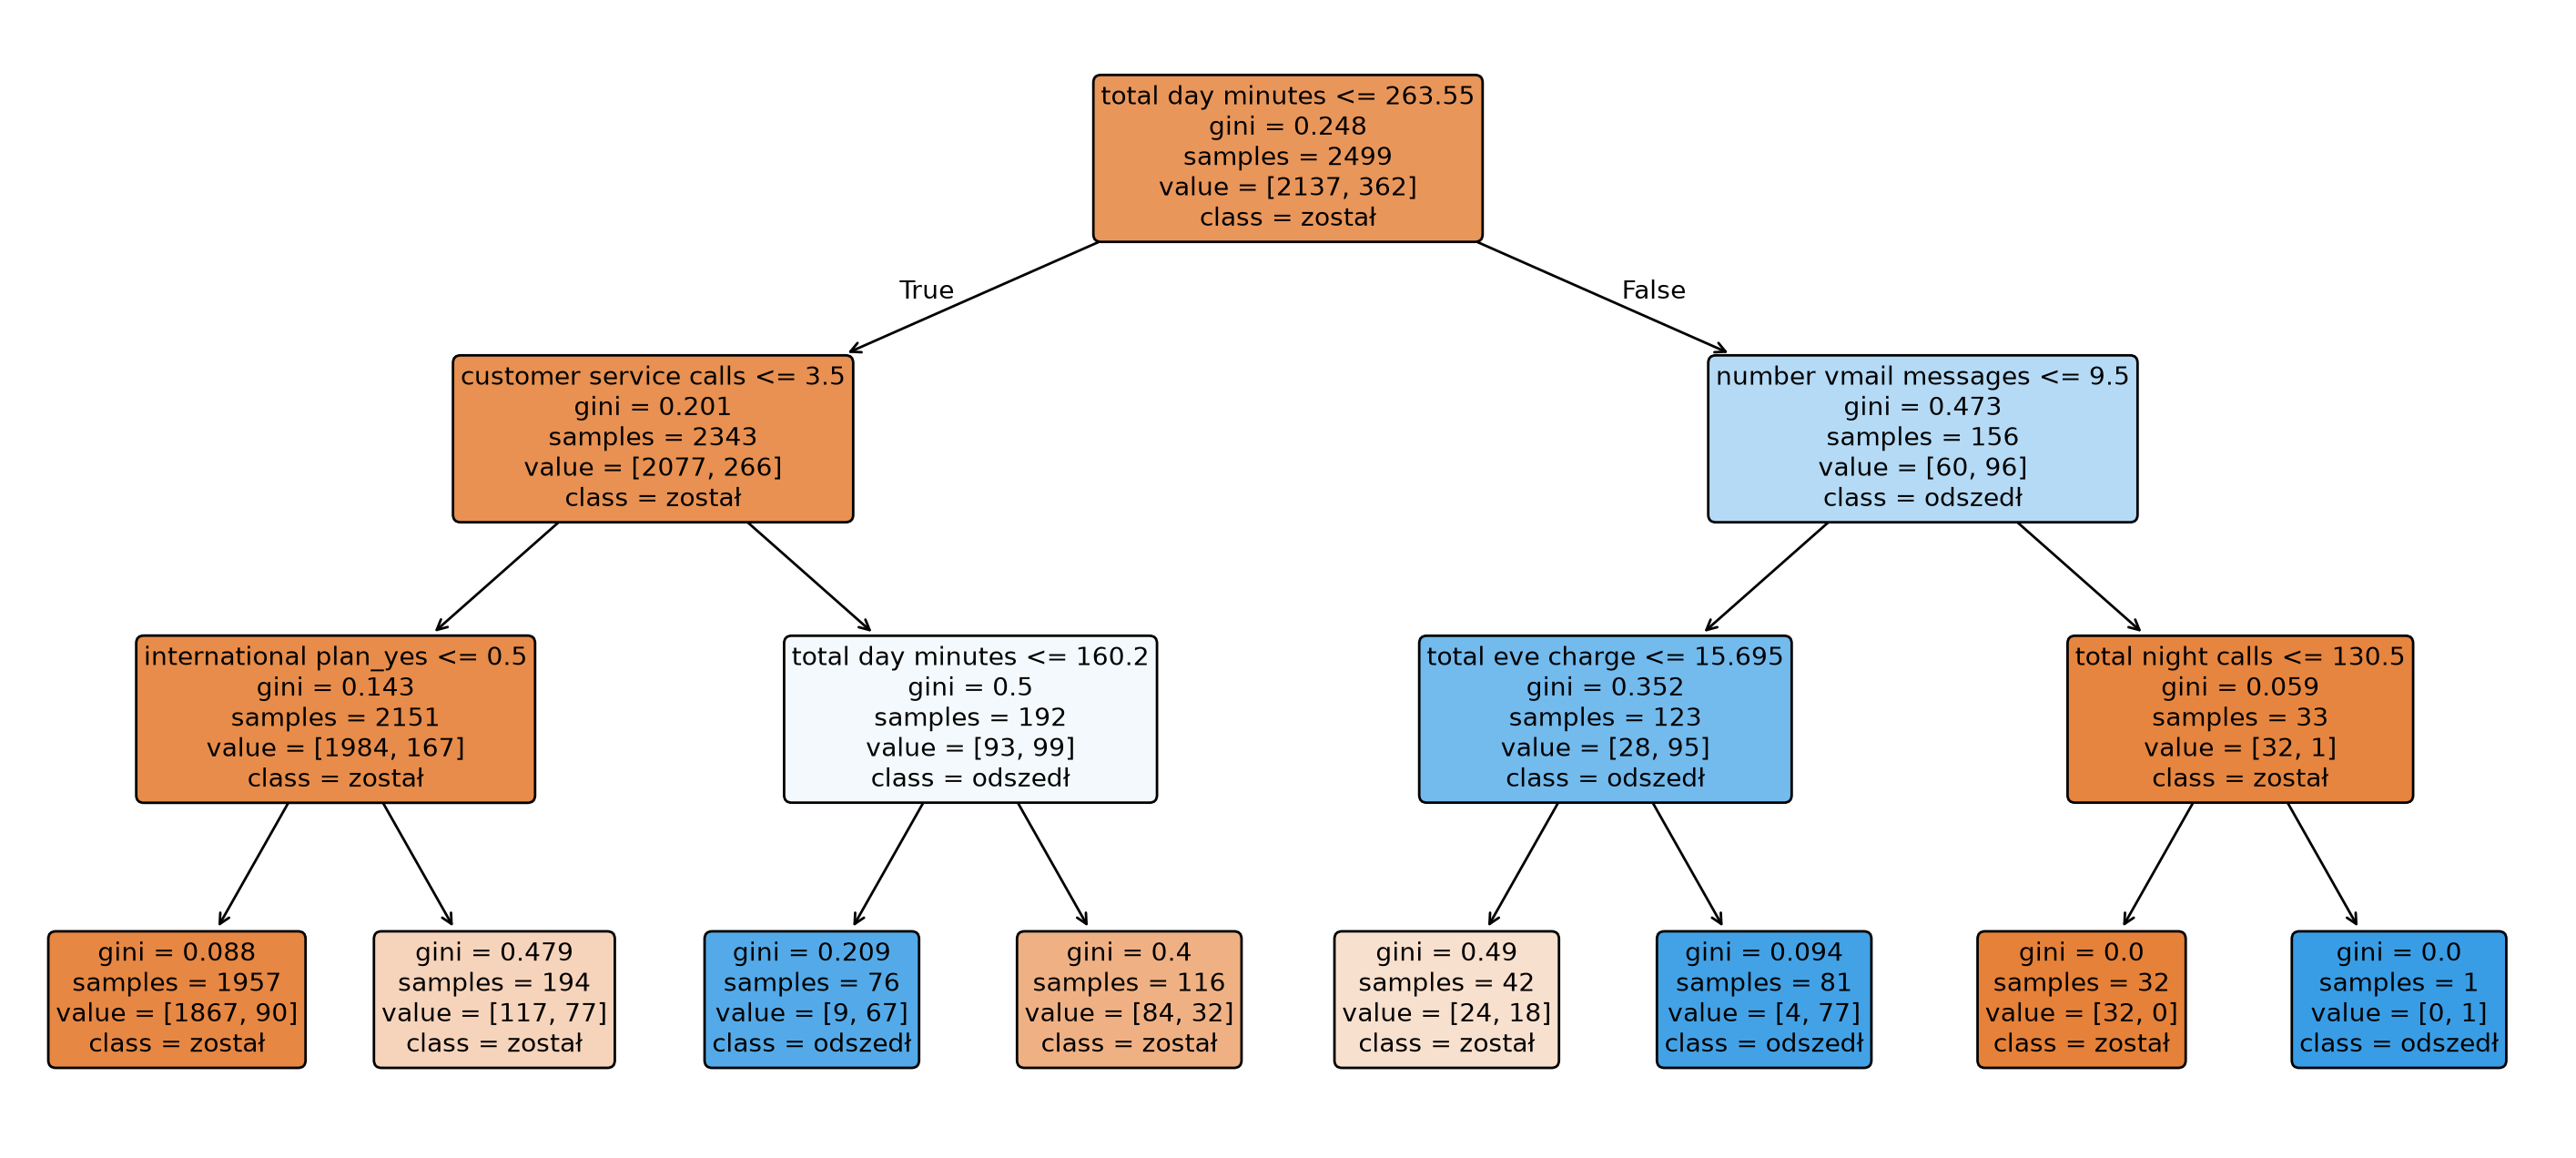

In [50]:
plt.figure(figsize=(18, 8), dpi=200)
plot_tree(model, feature_names=list(X.columns), class_names=['został', 'odszedł'],
          filled=True, rounded=True, fontsize=10)
plt.show()

**Jak to czytać:** kolejność w `class_names` musi odpowiadać kolejności klas w modelu (`model.classes_` to `[0, 1]`, czyli `['został', 'odszedł']`), inaczej opisy w liściach byłyby zamienione.

Reguły pokazują, kto jest zagrożony odejściem – zwykle klienci z dużą liczbą minut rozmów w ciągu dnia (zwłaszcza bez poczty głosowej), często kontaktujący się z obsługą klienta lub korzystający z planu międzynarodowego. Taką wiedzę biznes może wykorzystać (np. kierować oferty retencyjne do konkretnych grup).

## 5. Dane niezbalansowane – `class_weight`

Drzewo skupia się na klasie licznej, bo to ona wygrywa w większości węzłów. Argument `class_weight='balanced'` nadaje klasie rzadkiej większą wagę (odwrotnie proporcjonalną do jej liczności), więc błędy na klasie `odszedł` „kosztują” więcej.

In [34]:
def metryki(nazwa, model):
    y_p = model.predict(X_test)
    return {'model': nazwa,
            'accuracy': round(model.score(X_test, y_test), 3),
            'precision': round(precision_score(y_test, y_p, zero_division=0), 3),
            'recall': round(recall_score(y_test, y_p), 3),
            'F1': round(f1_score(y_test, y_p, zero_division=0), 3)}

model_bal = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42).fit(X_train, y_train)

pd.DataFrame([metryki('baseline', baseline),
              metryki('drzewo max_depth=3', model),
              metryki("drzewo max_depth=3, class_weight='balanced'", model_bal)]).set_index('model')

,accuracy,precision,recall,F1
model,,,,
baseline,0.855,0.000,0.000,0.000
drzewo max_depth=3,0.922,0.798,0.620,0.698
"drzewo max_depth=3, class_weight='balanced'",0.784,0.380,0.769,0.508


Ważenie klas **podnosi recall** (wykrywamy więcej odchodzących klientów), ale zwykle **obniża precision** (więcej fałszywych alarmów) i accuracy. To kompromis – wybór zależy od kosztów biznesowych:
- jeśli oferta zatrzymująca jest tania, a utrata klienta droga – lepszy jest wysoki recall,
- jeśli kontakt z każdym „podejrzanym” klientem jest kosztowny – ważniejsza jest precision.

## 6. Dobór hiperparametrów (`GridSearchCV`)

Zamiast zgadywać `max_depth` i inne ustawienia, możemy przeszukać siatkę wartości. `GridSearchCV` dla każdej kombinacji liczy wynik w **walidacji krzyżowej** (`cv=5`) na zbiorze treningowym i wybiera najlepszą. Jako metrykę wybieramy `f1`, a nie `accuracy`, bo dane są niezbalansowane. Szczegóły metody poznamy w rozdziałach 4.4 i 4.5.

In [35]:
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8],
    'min_samples_leaf': [1, 5, 10, 20, 50],
    'criterion': ['gini', 'entropy'],
}

gs = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid=param_grid,
                  scoring='f1', cv=5, n_jobs=-1)
gs.fit(X_train, y_train)

print('Najlepszy F1 (walidacja krzyżowa):', round(gs.best_score_, 3))
print('Najlepsze parametry:', gs.best_params_)

Najlepszy F1 (walidacja krzyżowa): 0.803
Najlepsze parametry: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 10}


In [36]:
najlepszy = gs.best_estimator_

pd.DataFrame([metryki('drzewo max_depth=3', model),
              metryki('najlepsze z GridSearchCV', najlepszy)]).set_index('model')

,accuracy,precision,recall,F1
model,,,,
drzewo max_depth=3,0.922,0.798,0.620,0.698
najlepsze z GridSearchCV,0.932,0.808,0.694,0.747


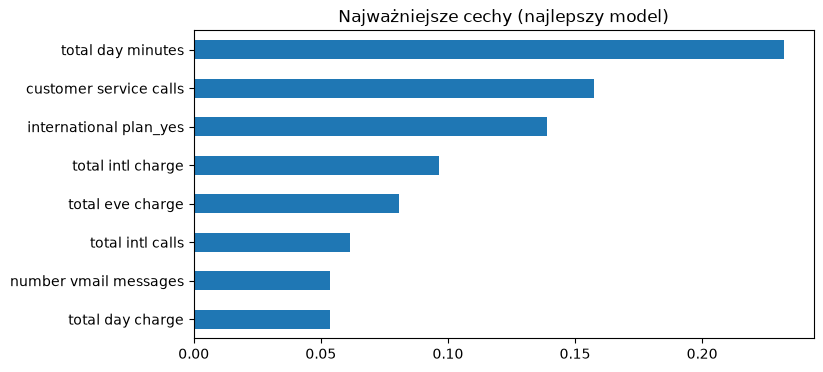

In [37]:
waznosc = pd.Series(najlepszy.feature_importances_, index=X.columns).sort_values().tail(8)
waznosc.plot.barh(figsize=(8, 4), title='Najważniejsze cechy (najlepszy model)')
plt.show()

Dobór hiperparametrów zwykle poprawia wynik względem „ręcznie” wybranego drzewa, ale tylko do pewnego stopnia – pojedyncze drzewo ma ograniczoną moc. Lepsze wyniki da **las losowy** (rozdział 4.2). Końcowy wynik oceniamy na zbiorze testowym, który nie brał udziału w doborze parametrów.

## 7. Podsumowanie

1. Zbiór jest **niezbalansowany** (ok. 14,5% odejść), więc `accuracy` jest mylące – baseline bez żadnej wiedzy ma ok. 85,5%.
2. Oceniamy model przez **recall, precision i F1** dla klasy, na której nam zależy.
3. `class_weight='balanced'` zwiększa czułość kosztem precyzji – wybór zależy od kosztów biznesowych.
4. `GridSearchCV` automatyzuje dobór hiperparametrów; przy niezbalansowanych danych wybieramy metrykę inną niż `accuracy`.
5. Pamiętajmy o poprawnej kolejności `class_names` względem `model.classes_`.